# KION: качество пользователей и подозрительные профили

Цель — понять, есть ли технические аномалии и какие пользователи требуют ручной проверки. **Флаги — эвристики, не доказательство ботов.** Ничего не удаляем и не меняем в обучении.

Основной анализ ограничен историей **до 2021-08-09**, то есть до validation-недели. Будущие просмотры и результаты holdout для отбора пользователей не используются. Сравниваем всех пользователей с доступной историей и исходную случайную выборку из 30 000.

Источник: полный `KION_DATASET/data_original.zip`. В нём одна агрегированная строка на user–item, дата последнего просмотра, суммарная длительность. Это **не журнал сеансов**: нельзя достоверно измерить число действий в секунду, пересечение сеансов или физически невозможные часы просмотра в конкретный день. Поставщик сообщает об анонимизации и добавлении случайного шума — см. локальный README датасета.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'KION_DATASET/data_original.zip').exists())
OUT = ROOT / 'baseline/artifacts/eda_users_20210809'
OUT.mkdir(parents=True, exist_ok=True)
CUTOFF = pd.Timestamp('2021-08-09')
SEED = 42
# При Run All в Jupyter display уже доступен; обычный Python печатает таблицу.
try:
    display
except NameError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__, 'matplotlib:', matplotlib.__version__)
print('Cutoff:', CUTOFF, '| output:', OUT)

def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close('all')

Python: 3.12.14 pandas: 3.1.0 numpy: 2.5.4 matplotlib: 3.11.2
Cutoff: 2021-08-09 00:00:00 | output: /home/guyder/Проекты/tbank-rnd/baseline/artifacts/eda_users_20210809


## 1. Загрузка и структурное качество

Для полного архива смотрим схему, дубли и связи идентификаторов. Все последующие пользовательские статистики считаются только по префиксу до cutoff. Некорректные строки показываются отдельно; они не превращаются автоматически в обвинение пользователя.

In [2]:
archive = ROOT / 'KION_DATASET/data_original.zip'
with zipfile.ZipFile(archive) as z:
    info = z.getinfo('data_original/interactions.csv')
    with z.open(info) as stream:
        raw = pd.read_csv(stream)
users = pd.read_csv(ROOT / 'KION_DATASET/data_original/users.csv')
items = pd.read_csv(ROOT / 'KION_DATASET/data_original/items.csv')
raw['date'] = pd.to_datetime(raw['last_watch_dt'], errors='coerce')
structural = pd.Series({
    'interaction_rows': len(raw), 'unique_users': raw.user_id.nunique(),
    'unique_items': raw.item_id.nunique(), 'user_metadata_rows': len(users),
    'item_metadata_rows': len(items), 'duplicate_user_item_rows': int(raw.duplicated(['user_id','item_id']).sum()),
    'duplicate_user_metadata_ids': int(users.user_id.duplicated().sum()),
    'duplicate_item_metadata_ids': int(items.item_id.duplicated().sum()),
    'missing_user_ids': int(raw.user_id.isna().sum()), 'missing_item_ids': int(raw.item_id.isna().sum()),
    'invalid_dates': int(raw.date.isna().sum()),
    'rows_without_user_metadata': int((~raw.user_id.isin(users.user_id)).sum()),
    'rows_without_item_metadata': int((~raw.item_id.isin(items.item_id)).sum()),
}, name='value')
display(structural.to_frame())
print('Observed dates:', raw.date.min(), '—', raw.date.max())
print('CSV member CRC:', info.CRC, 'uncompressed bytes:', info.file_size)
valid = raw.user_id.notna() & raw.item_id.notna() & raw.date.notna()
history = raw.loc[valid & (raw.date < CUTOFF)].copy()
sample = pd.read_csv(ROOT / 'baseline/artifacts/default/sample_users.csv').user_id
history['in_development_sample'] = history.user_id.isin(sample)
print('Historical rows:', len(history), 'users:', history.user_id.nunique())
print('Sample IDs:', len(sample), '| reproducible random sample:',
      np.array_equal(np.sort(np.random.default_rng(SEED).choice(np.sort(raw.user_id.unique()), len(sample), replace=False)), np.sort(sample)))
# Храним только структурные сведения о полном архиве; дальнейшая работа — с прошлым.
del raw
write_manifest = {'cutoff_exclusive': str(CUTOFF.date()), 'seed': SEED,
                  'archive_member_crc': info.CRC, 'archive_member_bytes': info.file_size,
                  'sample_sha256': hashlib.sha256((ROOT/'baseline/artifacts/default/sample_users.csv').read_bytes()).hexdigest(),
                  'versions': {'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__},
                  'structural': {k:int(v) for k,v in structural.items()}}
(OUT/'manifest.json').write_text(json.dumps(write_manifest, indent=2))

Observed dates: 2021-03-13 00:00:00 — 2021-08-22 00:00:00
CSV member CRC: 2781396479 uncompressed bytes: 180032258
Historical rows: 4649162 users: 850489
Sample IDs: 30000 | reproducible random sample: True


,value
interaction_rows,5476251
unique_users,962179
unique_items,15706
user_metadata_rows,840197
item_metadata_rows,15963
duplicate_user_item_rows,0
duplicate_user_metadata_ids,0
duplicate_item_metadata_ids,0
missing_user_ids,0
missing_item_ids,0


## 2. Размер и плотность истории

`n_pairs` — число наблюдаемых объектов; `active_dates` — число разных дат **последних** просмотров пар; `max_pairs_one_date` — максимальное число пар с одинаковой датой. Это индикаторы концентрации записей, а не восстановленная интенсивность реальных сеансов.

Top 0.1% users account for 3.08% of pairs
Top 1.0% users account for 13.75% of pairs
Top 5.0% users account for 34.68% of pairs


,n_pairs,active_dates,max_pairs_one_date,one_date_share,observed_span_days
0.0000,1.0000,1.0000,1.0000,0.0250,1.0000
0.2500,1.0000,1.0000,1.0000,0.3333,1.0000
0.5000,2.0000,2.0000,1.0000,0.6667,4.0000
0.7500,6.0000,4.0000,2.0000,1.0000,30.0000
0.9000,13.0000,8.0000,4.0000,1.0000,73.0000
0.9500,20.0000,12.0000,5.0000,1.0000,101.0000
0.9900,46.0000,24.0000,8.0000,1.0000,138.0000
0.9990,114.0000,48.0000,16.0000,1.0000,148.0000
1.0000,"1,267.0000",144.0000,250.0000,1.0000,149.0000


,users,user_share,interaction_share
n_pairs,,,
1,317396,0.3732,0.0683
2,132564,0.1559,0.0570
3–5,182426,0.2145,0.1483
6–10,110351,0.1298,0.1802
11–20,67245,0.0791,0.2080
21–50,33497,0.0394,0.2162
51–100,5802,0.0068,0.0830
101–500,1200,0.0014,0.0378
>500,8,0.0000,0.0012


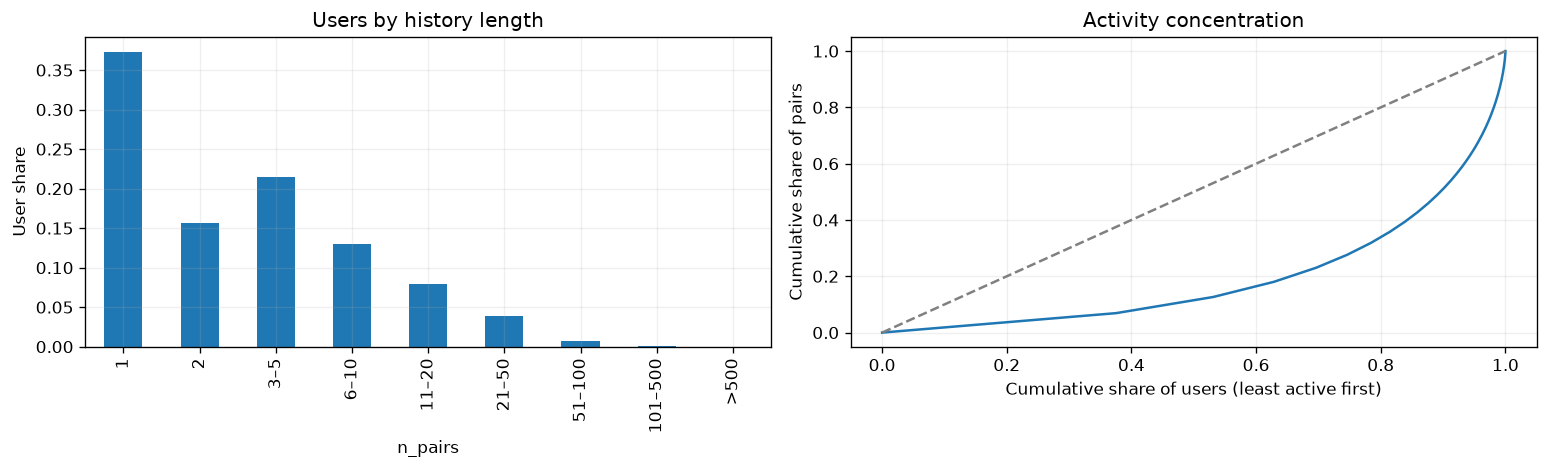

In [3]:
daily = history.groupby(['user_id','date']).size().rename('pairs')
profile = history.groupby('user_id').agg(n_pairs=('item_id','size'), n_items=('item_id','nunique'),
                                         first_date=('date','min'), last_date=('date','max'),
                                         active_dates=('date','nunique'))
profile['max_pairs_one_date'] = daily.groupby(level=0).max()
profile['observed_span_days'] = (profile.last_date-profile.first_date).dt.days+1
profile['last_seen_days'] = (CUTOFF-profile.last_date).dt.days
profile['one_date_share'] = profile.max_pairs_one_date/profile.n_pairs
profile['pairs_per_active_date'] = profile.n_pairs/profile.active_dates
profile['in_sample'] = profile.index.isin(sample)
quantiles = profile[['n_pairs','active_dates','max_pairs_one_date','one_date_share','observed_span_days']].quantile([0,.25,.5,.75,.9,.95,.99,.999,1])
display(quantiles)
activity_bins = pd.cut(profile.n_pairs, bins=[0,1,2,5,10,20,50,100,500,np.inf],
                       labels=['1','2','3–5','6–10','11–20','21–50','51–100','101–500','>500'])
activity = activity_bins.value_counts(sort=False).rename('users').to_frame()
activity['user_share'] = activity.users/len(profile)
activity['interaction_share'] = profile.groupby(activity_bins, observed=False).n_pairs.sum()/len(history)
display(activity)
fig, axes = plt.subplots(1,2,figsize=(13,4))
activity.user_share.plot.bar(ax=axes[0], title='Users by history length'); axes[0].set_ylabel('User share')
sorted_counts = np.sort(profile.n_pairs.to_numpy())
axes[1].plot(np.arange(1,len(sorted_counts)+1)/len(sorted_counts), np.cumsum(sorted_counts)/sorted_counts.sum())
axes[1].plot([0,1],[0,1], '--', color='gray'); axes[1].set(xlabel='Cumulative share of users (least active first)', ylabel='Cumulative share of pairs',title='Activity concentration')
show_plot('activity_concentration')
for fraction in [.001,.01,.05]:
    n = max(1,int(np.ceil(len(profile)*fraction)))
    print(f'Top {fraction:.1%} users account for {profile.n_pairs.nlargest(n).sum()/len(history):.2%} of pairs')

## 3. Случайная выборка против всей исторической популяции

Все попавшие в исходные 30 000 пользователи здесь учитываются независимо от активности в будущей неделе. Это другая популяция, чем 3328 пользователей, участвующих в validation-метрике. Для числа связей отсутствие истории к cutoff показываем явно.

Selected sample IDs without past history: 3396
Total variation distance (history-length bins): 0.004132876035640285


,users,pairs,mean_pairs,median_pairs,p99_pairs,single_pair_share,mean_active_dates,median_idle_days
population,,,,,,,,
all_history,850489,4649162,5.4665,2.0000,46.0000,0.3732,3.5343,35.0000
sample_with_history,26604,144278,5.4232,2.0000,47.0000,0.3751,3.5130,35.0000


,all_share,sample_share,difference_pp
n_pairs,,,
1,0.3732,0.3751,0.1864
2,0.1559,0.1571,0.1214
3–5,0.2145,0.2147,0.0172
6–10,0.1298,0.1284,-0.1386
11–20,0.0791,0.0782,-0.0883
21–50,0.0394,0.0377,-0.1722
51–100,0.0068,0.0077,0.0884
101–500,0.0014,0.0013,-0.0133
>500,0.0000,0.0000,-0.0009


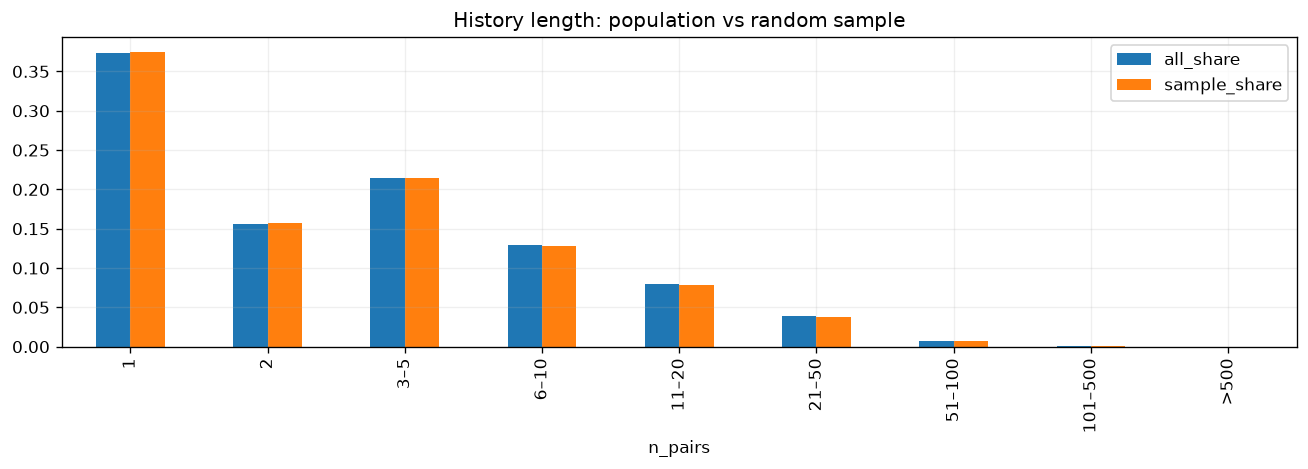

In [4]:
comparison_rows=[]
for name, part in [('all_history',profile),('sample_with_history',profile.loc[profile.in_sample])]:
    comparison_rows.append({'population':name,'users':len(part),'pairs':int(part.n_pairs.sum()),
                            'mean_pairs':part.n_pairs.mean(),'median_pairs':part.n_pairs.median(),
                            'p99_pairs':part.n_pairs.quantile(.99),'single_pair_share':part.n_pairs.eq(1).mean(),
                            'mean_active_dates':part.active_dates.mean(),'median_idle_days':part.last_seen_days.median()})
comparison=pd.DataFrame(comparison_rows).set_index('population')
display(comparison)
print('Selected sample IDs without past history:', len(sample)-int(profile.in_sample.sum()))
all_dist = activity_bins.value_counts(normalize=True,sort=False)
sample_dist = activity_bins.loc[profile.in_sample].value_counts(normalize=True,sort=False)
distribution_comparison = pd.DataFrame({'all_share':all_dist,'sample_share':sample_dist})
distribution_comparison['difference_pp'] = 100*(distribution_comparison.sample_share-distribution_comparison.all_share)
display(distribution_comparison)
print('Total variation distance (history-length bins):', .5*(all_dist-sample_dist).abs().sum())
distribution_comparison[['all_share','sample_share']].plot.bar(title='History length: population vs random sample')
show_plot('sample_representativeness')

## 4. Демография и пропуски

Отсутствие демографии не означает, что пользователь мусорный. Проверяем отдельно отсутствие всей строки и пропуски полей. Не интерпретируем возрастные/доходные интервалы как точные величины.

In [5]:
metadata_columns=['age','income','sex','kids_flg']
metadata = users.set_index('user_id')[metadata_columns]
if not metadata.index.is_unique:
    raise ValueError('Duplicate user metadata IDs require investigation before joining')
profile = profile.join(metadata, how='left')
profile['missing_metadata_row'] = ~profile.index.isin(metadata.index)
profile['missing_demographics_count'] = profile[metadata_columns].isna().sum(axis=1)
missing=pd.DataFrame({'all_missing_share':profile[metadata_columns].isna().mean(),
                      'sample_missing_share':profile.loc[profile.in_sample,metadata_columns].isna().mean()})
display(missing)
print('Users without metadata row:', int(profile.missing_metadata_row.sum()))
for field in metadata_columns:
    distribution=pd.DataFrame({'all':profile[field].astype('string').fillna('<missing>').value_counts(normalize=True),
                               'sample':profile.loc[profile.in_sample,field].astype('string').fillna('<missing>').value_counts(normalize=True)}).fillna(0)
    display(distribution.rename_axis(field))

Users without metadata row: 186824


,all_missing_share,sample_missing_share
age,0.2280,0.2307
income,0.2275,0.2304
sex,0.2288,0.2313
kids_flg,0.2197,0.2226


,all,sample
age,,
<missing>,0.2280,0.2307
age_25_34,0.2236,0.2219
age_35_44,0.1978,0.1963
age_45_54,0.1273,0.1264
age_18_24,0.1187,0.1182
age_55_64,0.0601,0.0601
age_65_inf,0.0446,0.0464


,all,sample
income,,
income_20_40,0.4369,0.4364
income_40_60,0.2347,0.2318
<missing>,0.2275,0.2304
income_60_90,0.0663,0.0654
income_0_20,0.0199,0.0209
income_90_150,0.0137,0.0139
income_150_inf,0.0011,0.0010


,all,sample
sex,,
Ж,0.3969,0.3940
М,0.3744,0.3747
<missing>,0.2288,0.2313


,all,sample
kids_flg,,
0.0,0.5383,0.5356
1.0,0.2420,0.2418
<missing>,0.2197,0.2226


## 5. Длительность и процент просмотра — только диагностика

Эти поля **не добавляются в обучающие признаки**. Суммарная длительность относится к паре, а не к последнему дню. Большая длительность может отражать сериал или повторные просмотры. Нулевой процент/короткая длительность могут отражать запуск, округление или шум — не доказательство технического аккаунта. Без словаря кодирования неизвестно, является ли watched_pct=100 цензурированием.

,total_dur,watched_pct
count,"4,649,162.0000","4,648,336.0000"
mean,"8,546.0284",47.6591
std,"50,373.9998",42.2755
min,1.0000,0.0000
1%,3.0000,0.0000
50%,"3,227.0000",36.0000
90%,"15,878.0000",100.0000
99%,"91,543.0000",100.0000
99.9%,"398,040.9070",100.0000
max,"80,411,672.0000",100.0000


,row_share
missing_duration,0.0000
negative_duration,0.0000
zero_duration,0.0000
duration_le_10,0.0377
missing_pct,0.0002
negative_pct,0.0000
zero_pct,0.1305
pct_over_100,0.0000


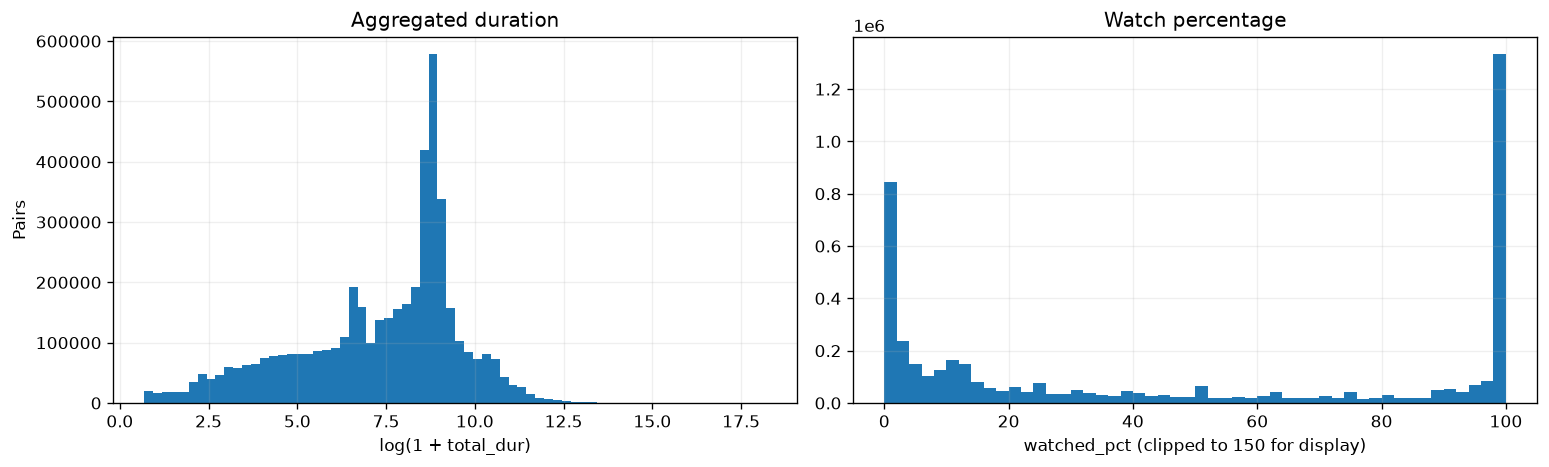

,user_id,item_id,title,content_type,date,total_dur,watched_pct
0,80682,874,Буренка Даша,series,2021-08-01,80411672,100.0000
1,546906,8157,Смешарики,series,2021-07-29,23007956,99.0000
2,345987,6968,Гримм,series,2021-05-25,9026441,100.0000
3,797869,7061,Как устроена Вселенная,series,2021-05-30,6147245,63.0000
4,47224,5533,Титаник,film,2021-05-30,5794161,100.0000
5,843846,11661,Презумпция виновности,film,2021-04-28,5748938,100.0000
6,383409,496,Воскресший Эртугрул,series,2021-07-16,5674805,65.0000
7,94586,496,Воскресший Эртугрул,series,2021-08-07,5441047,96.0000
8,99190,6192,Отчаянные домохозяйки,series,2021-07-11,4276955,99.0000
9,689509,7476,Анатомия страсти,series,2021-07-18,4001493,96.0000


,short_and_zero_share_threshold,users,sample_users
0,0.5000,91,4
1,0.8000,5,0
2,0.9500,0,0


In [6]:
duration=pd.to_numeric(history.total_dur,errors='coerce')
pct=pd.to_numeric(history.watched_pct,errors='coerce')
quality = pd.DataFrame({'total_dur':duration.describe(percentiles=[.01,.5,.9,.99,.999]),
                        'watched_pct':pct.describe(percentiles=[.01,.5,.9,.99,.999])})
display(quality)
row_flags=pd.DataFrame({'missing_duration':duration.isna(),'negative_duration':duration.lt(0),
                        'zero_duration':duration.eq(0),'duration_le_10':duration.between(0,10),
                        'missing_pct':pct.isna(),'negative_pct':pct.lt(0),'zero_pct':pct.eq(0),
                        'pct_over_100':pct.gt(100)}, index=history.index)
display(row_flags.mean().rename('row_share').to_frame())
profile['duration_available_pairs'] = duration.notna().groupby(history.user_id).sum()
profile['pct_available_pairs'] = pct.notna().groupby(history.user_id).sum()
profile['short_duration_share'] = duration.between(0,10).groupby(history.user_id).sum()/profile.duration_available_pairs.replace(0,np.nan)
profile['zero_pct_share'] = pct.eq(0).groupby(history.user_id).sum()/profile.pct_available_pairs.replace(0,np.nan)
profile['invalid_measurement_pairs'] = (duration.lt(0)|pct.lt(0)).groupby(history.user_id).sum()
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].hist(np.log1p(duration.loc[duration.ge(0)]),bins=70);axes[0].set(xlabel='log(1 + total_dur)',ylabel='Pairs',title='Aggregated duration')
axes[1].hist(pct.dropna().clip(0,150),bins=50);axes[1].set(xlabel='watched_pct (clipped to 150 for display)',title='Watch percentage')
show_plot('measurement_quality')
# Наиболее экстремальные пары: читаем названия, а не объявляем пользователя ботом.
extreme_pairs=history.loc[duration.nlargest(12).index].merge(
    items[['item_id','title','content_type']],on='item_id',how='left',validate='many_to_one')
display(extreme_pairs[['user_id','item_id','title','content_type','date','total_dur','watched_pct']])
extreme_pairs.to_csv(OUT/'extreme_duration_pairs.csv',index=False)
sensitivity=[]
for threshold in [.5,.8,.95]:
    mask=(profile.duration_available_pairs.ge(20)&profile.pct_available_pairs.ge(20)&
          profile.short_duration_share.ge(threshold)&profile.zero_pct_share.ge(threshold))
    sensitivity.append({'short_and_zero_share_threshold':threshold,'users':int(mask.sum()),
                        'sample_users':int((mask&profile.in_sample).sum())})
display(pd.DataFrame(sensitivity))


## 6. Даты и синхронные всплески

Смотрим пики числа пар и долю пользователей, у которых все записи сосредоточены на одном дне. Общий пик может быть следствием премьеры, загрузки данных или особенностей выгрузки. Для вывода о ботах этих сведений недостаточно.

,pairs,users,items
date,,,
2021-06-30,67749,49793,3581
2021-08-01,62128,37551,4160
2021-08-08,61454,37291,4229
2021-07-31,59499,36428,4228
2021-08-07,59316,35906,4164
2021-06-16,57686,43768,3232
2021-07-25,54378,33151,4234
2021-07-18,54139,33139,4185
2021-07-01,53900,37923,3587


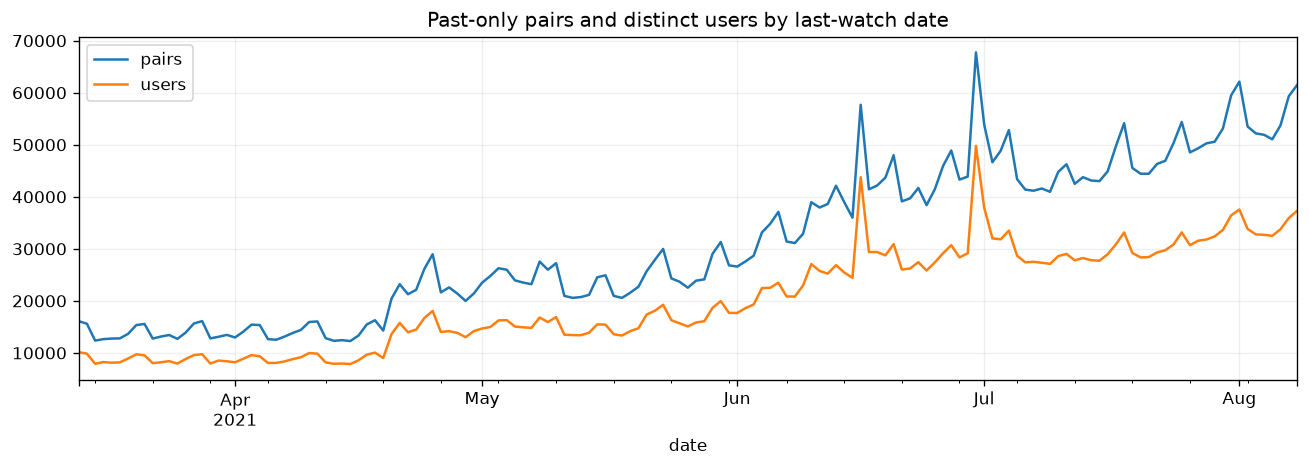

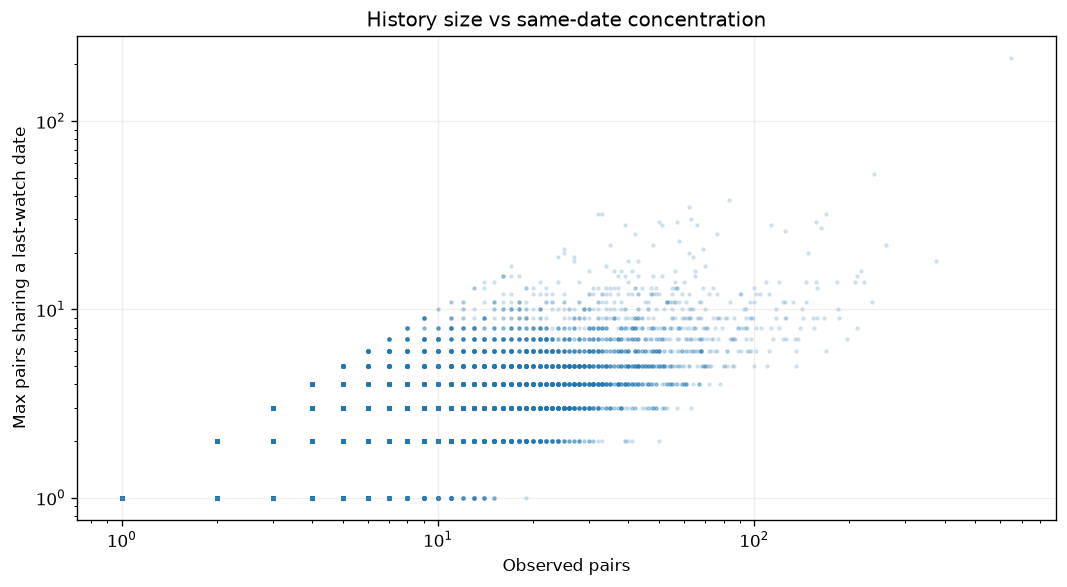

In [7]:
by_date=history.groupby('date').agg(pairs=('user_id','size'), users=('user_id','nunique'),items=('item_id','nunique'))
display(by_date.nlargest(10,'pairs'))
by_date[['pairs','users']].plot(title='Past-only pairs and distinct users by last-watch date')
show_plot('calendar_spikes')
fig,ax=plt.subplots(figsize=(9,5))
points=profile.sample(min(40000,len(profile)),random_state=SEED)
ax.scatter(points.n_pairs,points.max_pairs_one_date,s=3,alpha=.15)
ax.set(xscale='log',yscale='log',xlabel='Observed pairs',ylabel='Max pairs sharing a last-watch date',title='History size vs same-date concentration')
show_plot('same_date_concentration')

## 7. Совпадающие наборы объектов

Ищем точные совпадения наборов у пользователей с минимум 10 объектами. Короткие истории не проверяем: совпадения популярных фильмов ожидаемы. Быстрый хеш используется только для поиска кандидатов; затем сравниваем точные отсортированные item_id. Совпадение может быть естественным или вызванным шумом/подготовкой данных, поэтому сохраняем примеры, а не удаляем пользователей.

In [8]:
hashes=pd.util.hash_pandas_object(history.item_id,index=False)
signature=pd.DataFrame({'user_id':history.user_id.to_numpy(),'hash':hashes.to_numpy()}).groupby('user_id')['hash'].sum().to_frame()
signature['n_items']=profile.n_items
potential=signature.loc[signature.n_items.ge(10)]
potential=potential.loc[potential.duplicated(['hash','n_items'],keep=False)]
exact_groups=[]
if len(potential):
    exact=history.loc[history.user_id.isin(potential.index)].sort_values(['user_id','item_id']).groupby('user_id').item_id.agg(tuple)
    grouped={}
    for user, sequence in exact.items():
        grouped.setdefault(sequence,[]).append(int(user))
    for sequence, ids in grouped.items():
        if len(ids)>1:
            exact_groups.append({'n_users':len(ids),'n_items':len(sequence),'user_ids':ids,'item_ids':list(sequence)})
exact_groups.sort(key=lambda g:(-g['n_users'],-g['n_items']))
profile['identical_history_group_size']=0
for group in exact_groups:
    profile.loc[group['user_ids'],'identical_history_group_size']=group['n_users']
print('Exact matching history groups (>=10 items):',len(exact_groups))
print('Users in those groups:',int(profile.identical_history_group_size.gt(1).sum()))
display(pd.DataFrame([{k:v for k,v in g.items() if k!='item_ids'} for g in exact_groups[:20]]))
(OUT/'identical_history_groups.json').write_text(json.dumps(exact_groups,ensure_ascii=False,indent=2))

Exact matching history groups (>=10 items): 2
Users in those groups: 5


,n_users,n_items,user_ids
0,3,11,"[325923, 531898, 617488]"
1,2,10,"[846495, 849665]"


## 8. Прозрачные эвристики для ручной проверки

Пороги заданы заранее и не оптимизируются по качеству рекомендаций:

- `heavy_tail`: число пар не меньше max(100, p99.9). Сам по себе это нормальный тяжёлый хвост.
- `same_date_burst`: минимум 50 пар имеют одну дату и это не менее 80% истории.
- `compressed_history`: ≥100 объектов, ≤5 разных дат и ≥50 пар на одну дату. Это концентрация агрегированных записей, не восстановленные сеансы.
- `mostly_short`: минимум 20 известных длительностей, не менее 95% из них ≤10; дополнительно известно ≥20 процентов, ≥95% которых нулевые.
- `identical_history`: точный набор ≥10 объектов совпадает с другим пользователем.
- `invalid_measurements`: отрицательная длительность или процент. Это проблема записи, не обязательно пользователя.

Отсутствие демографии и короткая история **не включены** в флаги. Таблица — очередь ручного разбора; сумма флагов не является вероятностью бота.

In [9]:
heavy_threshold=max(100,float(profile.n_pairs.quantile(.999)))
flags=pd.DataFrame(index=profile.index)
flags['heavy_tail']=profile.n_pairs.ge(heavy_threshold)
flags['same_date_burst']=profile.max_pairs_one_date.ge(50)&profile.one_date_share.ge(.8)
flags['compressed_history'] = profile.n_pairs.ge(100) & profile.active_dates.le(5) & profile.max_pairs_one_date.ge(50)
flags['mostly_short']=(profile.duration_available_pairs.ge(20)&profile.pct_available_pairs.ge(20)&
                       profile.short_duration_share.ge(.95)&profile.zero_pct_share.ge(.95))
flags['identical_history']=profile.identical_history_group_size.gt(1)
flags['invalid_measurements']=profile.invalid_measurement_pairs.gt(0)
profile['review_flag_count']=flags.sum(axis=1)
profile['review_reasons'] = ''
for reason in flags:
    profile['review_reasons'] += np.where(flags[reason], reason + ', ', '')
profile['review_reasons'] = profile.review_reasons.str.rstrip(', ')
flag_summary=pd.DataFrame({'all_users':flags.sum(),'sample_users':flags.loc[profile.in_sample].sum()})
flag_summary['all_user_share']=flag_summary.all_users/len(profile)
flag_summary['sample_user_share']=flag_summary.sample_users/profile.in_sample.sum()
flag_summary['all_pair_share']=[profile.loc[flags[c],'n_pairs'].sum()/len(history) for c in flags]
display(flag_summary)
print('Heavy threshold:',heavy_threshold)
print('Any review flag:',int(profile.review_flag_count.gt(0).sum()),'users;',int(profile.loc[profile.in_sample,'review_flag_count'].gt(0).sum()),'in sample')
print('Two or more flags:',int(profile.review_flag_count.ge(2).sum()))
print('Heavy tail + same-date burst:',int((flags.heavy_tail&flags.same_date_burst).sum()))
review=profile.loc[profile.review_flag_count.gt(0)].sort_values(['review_flag_count','n_pairs'],ascending=False)
review_columns=['n_pairs','active_dates','max_pairs_one_date','one_date_share','short_duration_share','zero_pct_share','missing_demographics_count','in_sample','review_reasons']
display(review[review_columns].head(30))
profile.join(flags.add_prefix('flag_')).to_csv(OUT/'user_profiles.csv')
review[review_columns].to_csv(OUT/'review_users.csv')
flag_summary.to_csv(OUT/'flag_summary.csv')
comparison.to_csv(OUT/'sample_comparison.csv')
activity.to_csv(OUT/'activity_distribution.csv')
summary={'historical_users':len(profile),'historical_pairs':len(history),'sample_users_with_history':int(profile.in_sample.sum()),
         'heavy_threshold':heavy_threshold,'any_flag_users':int(profile.review_flag_count.gt(0).sum()),
         'sample_any_flag_users':int(profile.loc[profile.in_sample,'review_flag_count'].gt(0).sum()),
         'two_or_more_flags':int(profile.review_flag_count.ge(2).sum()),
         'flag_counts':{k:int(v) for k,v in flags.sum().items()},
         'flag_pair_shares':{k:float(profile.loc[flags[k],'n_pairs'].sum()/len(history)) for k in flags},
         'single_pair_share':float(profile.n_pairs.eq(1).mean()),'max_pairs':int(profile.n_pairs.max()),
         'max_pairs_one_date':int(profile.max_pairs_one_date.max()),
         'sample_activity_total_variation':float(.5*(all_dist-sample_dist).abs().sum())}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))

Heavy threshold: 114.0
Any review flag: 876 users; 28 in sample
Two or more flags: 1
Heavy tail + same-date burst: 0


,all_users,sample_users,all_user_share,sample_user_share,all_pair_share
heavy_tail,864,27,0.0010,0.0010,0.0311
same_date_burst,7,0,0.0000,0.0000,0.0001
compressed_history,1,0,0.0000,0.0000,0.0001
mostly_short,0,0,0.0000,0.0000,0.0000
identical_history,5,1,0.0000,0.0000,0.0000
invalid_measurements,0,0,0.0000,0.0000,0.0000


,n_pairs,active_dates,max_pairs_one_date,one_date_share,short_duration_share,zero_pct_share,missing_demographics_count,in_sample,review_reasons
user_id,,,,,,,,,
649885,416,4,250,0.6010,0.2837,0.5048,4,False,"heavy_tail, compressed_history"
416206,1267,108,122,0.0963,0.0055,0.5028,0,False,heavy_tail
1010539,733,96,34,0.0464,0.0532,0.3943,4,False,heavy_tail
11526,675,89,28,0.0415,0.0000,0.0370,0,False,heavy_tail
555233,650,42,215,0.3308,0.2415,0.6569,0,False,heavy_tail
1057189,579,51,58,0.1002,0.1503,0.4066,0,False,heavy_tail
409259,575,73,24,0.0417,0.0000,0.0852,4,False,heavy_tail
473766,545,69,28,0.0514,0.1083,0.2463,4,False,heavy_tail
400913,531,117,16,0.0301,0.0678,0.1563,0,False,heavy_tail


## 9. Разбор конкретного пользователя

Выберите `USER_ID` и перезапустите ячейку. Показывается только доступное прошлое; есть названия объектов, тип, дата и диагностические поля. Разные эпизоды сериалов могут отсутствовать как отдельные события, а повторные просмотры агрегированы.

,n_pairs,active_dates,max_pairs_one_date,one_date_share,short_duration_share,zero_pct_share,missing_demographics_count,in_sample,review_reasons
user_id,,,,,,,,,
649885,416,4,250,0.6010,0.2837,0.5048,4,False,"heavy_tail, compressed_history"


,item_id,title,content_type,date,total_dur,watched_pct,genres
358,496,Воскресший Эртугрул,series,2021-07-18,40,0.0000,"боевики, драмы, приключения"
68,3182,Ральф против Интернета,film,2021-07-18,855,13.0000,"мультфильм, приключения, фантастика, семейное, комедии"
39,8784,Скандал,series,2021-07-18,237,0.0000,"драмы, триллеры"
389,16270,Тайна Коко,film,2021-07-18,742,12.0000,"мультфильм, фэнтези, приключения"
395,14,Жестокий Стамбул,series,2021-07-07,7,0.0000,драмы
75,24,Перебежчик,series,2021-07-07,3,0.0000,"драмы, историческое, военные"
12,47,Драка в блоке 99,film,2021-07-07,145,2.0000,"боевики, драмы, триллеры, криминал"
274,66,Три дня на побег,film,2021-07-07,53,1.0000,"боевики, драмы, триллеры"
108,135,Паранормальное явление 2,film,2021-07-07,61,1.0000,"ужасы, триллеры"
162,447,Золушка (цветная версия),film,2021-07-07,80,2.0000,"мелодрамы, семейное, комедии"


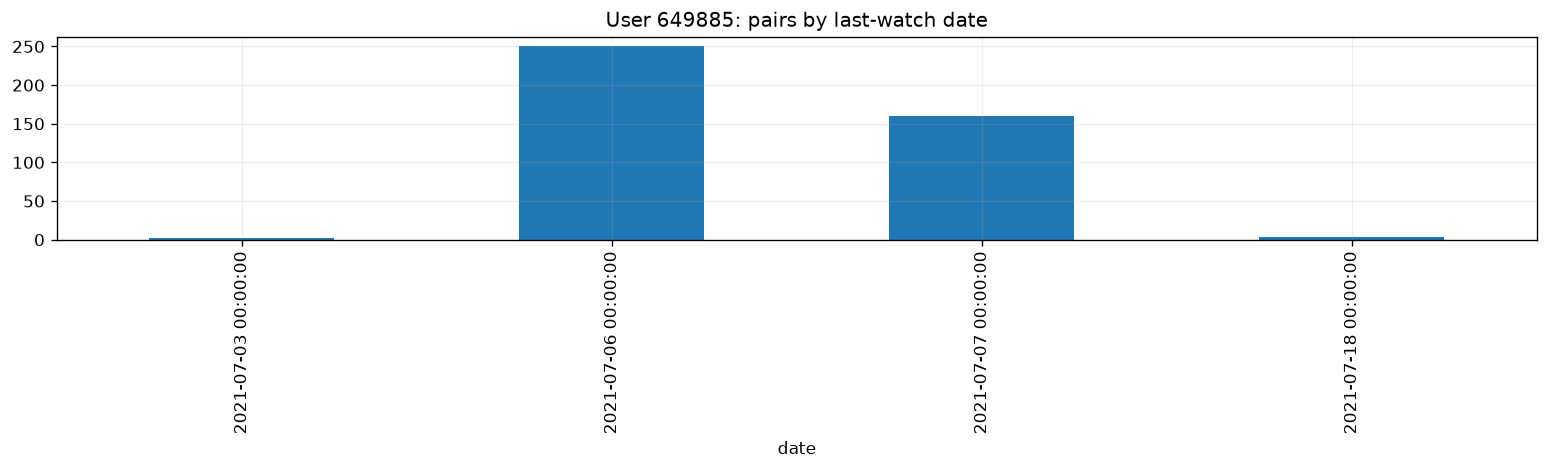

In [10]:
USER_ID = int(review.index[0]) if len(review) else int(profile.n_pairs.idxmax())
display(profile.loc[[USER_ID],review_columns])
user_history=history.loc[history.user_id.eq(USER_ID)].merge(
    items[['item_id','title','content_type','genres','release_year']],on='item_id',how='left',validate='many_to_one')
display(user_history.sort_values(['date','item_id'],ascending=[False,True])[
    ['item_id','title','content_type','date','total_dur','watched_pct','genres']].head(60))
user_history.groupby('date').size().plot.bar(title=f'User {USER_ID}: pairs by last-watch date',figsize=(13,4))
show_plot('example_user_dates')

## Выводы по выполненному анализу
Числа ниже вычисляются из таблиц выше; флаги не используются для изменения обучения.

In [11]:
print(f'Проверено прошлое {len(profile):,} пользователей и {len(history):,} пар до {CUTOFF.date()}.')
print(f'Случайная выборка: {profile.in_sample.sum():,} пользователей уже имеют историю; распределение активности близко к общему (TV={.5*(all_dist-sample_dist).abs().sum():.4f}).')
print(f'Короткие истории: {profile.n_pairs.eq(1).mean():.2%} имеют один объект; медиана {profile.n_pairs.median():.0f}. Это разреженность, не мусор.')
print(f'Очередь проверки: {(profile.review_flag_count>0).sum():,} пользователей; из них {(profile.loc[profile.in_sample,"review_flag_count"]>0).sum()} в выборке.')
print(f'Совпадающие наборы >=10 объектов: {len(exact_groups)} группы; совпадения надо разбирать с учётом популярности контента.')
print('Боты или технические аккаунты по этой выгрузке не установлены. Есть профили с сильной концентрацией записей; их стоит разбирать вручную.')
print('Примеры с концентрацией истории:')
display(profile.loc[flags.compressed_history,review_columns].sort_values('max_pairs_one_date',ascending=False).head(15))
print('Флаги внутри исходной случайной выборки:')
display(review.loc[review.in_sample,review_columns].head(30))


Проверено прошлое 850,489 пользователей и 4,649,162 пар до 2021-08-09.
Случайная выборка: 26,604 пользователей уже имеют историю; распределение активности близко к общему (TV=0.0041).
Короткие истории: 37.32% имеют один объект; медиана 2. Это разреженность, не мусор.
Очередь проверки: 876 пользователей; из них 28 в выборке.
Совпадающие наборы >=10 объектов: 2 группы; совпадения надо разбирать с учётом популярности контента.
Боты или технические аккаунты по этой выгрузке не установлены. Есть профили с сильной концентрацией записей; их стоит разбирать вручную.
Примеры с концентрацией истории:
Флаги внутри исходной случайной выборки:


,n_pairs,active_dates,max_pairs_one_date,one_date_share,short_duration_share,zero_pct_share,missing_demographics_count,in_sample,review_reasons
user_id,,,,,,,,,
649885,416,4,250,0.6010,0.2837,0.5048,4,False,"heavy_tail, compressed_history"


,n_pairs,active_dates,max_pairs_one_date,one_date_share,short_duration_share,zero_pct_share,missing_demographics_count,in_sample,review_reasons
user_id,,,,,,,,,
149693,250,62,22,0.0880,0.2400,0.2560,0,True,heavy_tail
650328,248,65,15,0.0605,0.0121,0.0806,0,True,heavy_tail
967506,238,88,14,0.0588,0.0924,0.2101,3,True,heavy_tail
161942,237,54,18,0.0759,0.0380,0.0970,0,True,heavy_tail
49507,212,46,19,0.0896,0.0613,0.1887,0,True,heavy_tail
323312,196,64,12,0.0612,0.0102,0.0510,0,True,heavy_tail
63695,186,58,9,0.0484,0.0108,0.1237,0,True,heavy_tail
691436,183,44,12,0.0656,0.1202,0.3224,0,True,heavy_tail
490197,176,12,29,0.1648,0.1080,0.3580,4,True,heavy_tail


## 10. Как интерпретировать результаты

1. Сначала отделяем технические ошибки (дубли ключей, неизвестные item_id, некорректные даты) от статистических аномалий.
2. Высокая активность, пропуски демографии, совпадения популярных наборов и короткие просмотры по отдельности не доказывают мусорный профиль.
3. Для подозрительных случаев нужны ручной разбор и, в идеале, настоящие event-level логи. В этой выгрузке их нет.
4. Если решим проверять фильтрацию, правила вычисляем только по прошлому каждого cutoff. Сначала меняем только train и сравниваем на неизменной validation-популяции. Фильтрация validation по тем же правилам — отдельная условная метрика с обязательным отчётом о потерянном покрытии.
5. Длительность и watched_pct использованы здесь исключительно для диагностики. Текущие признаки, модели, списки пользователей и кандидаты не изменены.

Все таблицы и графики экспортированы в `baseline/artifacts/eda_users_20210809/`. Чтобы воспроизвести анализ в Jupyter, выберите Python из `baseline/.venv` (для интерактивного запуска потребуется ipykernel).